[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/07_multiple_sequence_alignment.ipynb)

# 07 · Multiple Sequence Alignment: I/O and Analysis

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~50 min*

A multiple sequence alignment (MSA) lines up many related sequences so that each column holds
residues that share an evolutionary (and usually structural) position. MSAs reveal which residues
evolution keeps fixed, and in drug discovery, which binding-site residues differ between a target and
its off-targets. We use an MSA of **15 kinase domains** (`data/alignments/`), built with the FAMSA
aligner from the UniProt sequences in `data/sequences/kinase_domains.fasta`.

**Learning objectives.** By the end of this notebook you will be able to:

- read, slice, and write multiple sequence alignments with `Bio.AlignIO` and `Bio.Align`
- compute per-column conservation (Shannon entropy) and a consensus sequence
- map residue numbers of one protein onto alignment columns
- relate conservation of binding-site residues to inhibitor selectivity

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython', 'pyfamsa'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Reading an alignment

In [2]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import AlignIO, Align, SeqIO

msa = AlignIO.read(f"{DATA_DIR}/alignments/kinase_domains_famsa.aln", "clustal")
print(msa)

Alignment with 15 rows and 377 columns
FKKIKVLGSGAFGTVYKGLWIPEGEK--VKIPVAIKELREAT--...--- EGFR_HUMAN
LRKVKVLGSGAFGTVYKGIWIPDGEN--VKIPVAIKVLRENT--...--- ERBB2_HUMAN
LRKLKVLGSGVFGTVHKGVWIPEGES--IKIPVCIKVIEDKS--...--- ERBB3_HUMAN
LKRVKVLGSGAFGTVYKGIWVPEGET--VKIPVAIKILNETT--...--- ERBB4_HUMAN
FKKIKVLGSGAFGTVYKGLWIPEGEK--VKIPVAIKELREAT--...--- EGFR_MOUSE
LRKGGVLGMGAFGRVYKGVWVPEGEN--VKIPVAIKELLKST--...--- EGFR_DROME
TKLDKKLGAGAFGTVFAGIYYPKRAK-NVKIPVAIKVFQTDQ--...--- LET23_CAEEL
ITMKHKLGGGQYGEVYEGVWKKYSLT------VAVKTLKEDT--...--- ABL1_HUMAN
LRLEVKLGQGCFGEVWMGTWNGT--T-----RVAIKTLKPGT--...--- SRC_HUMAN
ITVGQRIGSGSFGTVYKGKWHGD---------VAVKMLNVTA-P...--- BRAF_HUMAN
LKLGKPLGRGAFGQVIEADAFGIDKTA-TCRTVAVKMLKEGA--...--- VGFR2_HUMAN
LTFLKELGTGQFGVVKYGKWRGQ--Y-----DVAIKMIKEGS--...--- BTK_HUMAN
FQKVEKIGEGTYGVVYKARNKLTGEV------VALKKIRLDTE-...PFF CDK2_HUMAN
VHFNEVIGRGHFGCVYHGTLLDNDGK---KIHCAVKSLNRIT--...--- MET_HUMAN
ITLIRGLGHGAFGEVYEGQVSGMPND-PSPLQVAVKTLPEVC--...--- ALK_HUMAN


In [3]:
print("sequences:", len(msa), "| columns:", msa.get_alignment_length())
for rec in msa[:3]:
    print(rec.id, rec.seq[:50])

sequences: 15 | columns: 377
EGFR_HUMAN FKKIKVLGSGAFGTVYKGLWIPEGEK--VKIPVAIKELREAT--SPKANK
ERBB2_HUMAN LRKVKVLGSGAFGTVYKGIWIPDGEN--VKIPVAIKVLRENT--SPKANK
ERBB3_HUMAN LRKLKVLGSGVFGTVHKGVWIPEGES--IKIPVCIKVIEDKS--GRQSFQ


`AlignIO` returns a `MultipleSeqAlignment`: a list of gapped `SeqRecord`s. Slicing works like a
2-D array: `msa[rows, columns]`.

In [4]:
print(msa[:5, 0:30])
print("column 7:", msa[:, 7])

Alignment with 5 rows and 30 columns
FKKIKVLGSGAFGTVYKGLWIPEGEK--VK EGFR_HUMAN
LRKVKVLGSGAFGTVYKGIWIPDGEN--VK ERBB2_HUMAN
LRKLKVLGSGVFGTVHKGVWIPEGES--IK ERBB3_HUMAN
LKRVKVLGSGAFGTVYKGIWVPEGET--VK ERBB4_HUMAN
FKKIKVLGSGAFGTVYKGLWIPEGEK--VK EGFR_MOUSE
column 7: GGGGGGGGGGGGGGG


Biopython also has the newer `Bio.Align.Alignment` class (via `Align.read` or `msa.alignment`), which
stores ungapped sequences plus coordinates and converts easily to a NumPy array.

In [5]:
aln = Align.read(f"{DATA_DIR}/alignments/kinase_domains_famsa.aln", "clustal")
names = [s.id for s in aln.sequences]
arr = np.array(aln, dtype="U")      # rows = sequences, columns = alignment positions
print(type(aln).__name__, arr.shape)

Alignment (15, 377)


## 2. Writing other formats

In [6]:
import os
os.makedirs("output", exist_ok=True)
for fmt, ext in [("fasta", "fasta"), ("stockholm", "sto"), ("phylip-relaxed", "phy")]:
    AlignIO.write(msa, f"output/kinases.{ext}", fmt)
    print(fmt, "->", open(f"output/kinases.{ext}").read()[:80].replace("\n", " | "))

fasta -> >EGFR_HUMAN | FKKIKVLGSGAFGTVYKGLWIPEGEK--VKIPVAIKELREAT--SPKANKEILDEAYVMA | SVDNP-H
stockholm -> # STOCKHOLM 1.0 | #=GF SQ 15 | EGFR_HUMAN FKKIKVLGSGAFGTVYKGLWIPEGEK--VKIPVAIKELREAT
phylip-relaxed ->  15 377 | EGFR_HUMAN   FKKIKVLGSG AFGTVYKGLW IPEGEK--VK IPVAIKELRE AT--SPKANK | ERBB


## 3. Conservation: Shannon entropy per column

For a column with residue frequencies *pᵢ*, entropy *H = −Σ pᵢ log₂ pᵢ*. *H = 0* means fully conserved;
higher values mean variable. Columns that are mostly gaps are excluded.

In [7]:
def column_entropy(col):
    residues = [c for c in col if c != "-"]
    counts = np.array(list(Counter(residues).values()), dtype=float)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

gap_frac = (arr == "-").mean(axis=0)
entropy = np.array([column_entropy(arr[:, j]) for j in range(arr.shape[1])])
entropy[gap_frac > 0.5] = np.nan
print("fully conserved columns:", int(np.sum(entropy == 0)), "of", int(np.sum(~np.isnan(entropy))), "scored columns")

fully conserved columns: 18 of 265 scored columns


## 4. A consensus sequence

In [8]:
def consensus(arr, threshold=0.7):
    out = []
    for j in range(arr.shape[1]):
        col = [c for c in arr[:, j] if c != "-"]
        if not col:
            continue
        aa, n = Counter(col).most_common(1)[0]
        out.append(aa if n / arr.shape[0] >= threshold else "x")
    return "".join(out)

cons = consensus(arr)
print(cons[:80])
print("strictly conserved (100%):", consensus(arr, 1.0).replace("x", "")[:40], "...")

xxxxxxLGxGxFGxVxxGxxxxxxxxxxxxxxVAxKxLxxxxxxxxxxxxxxxxExxxxxxxxHxxxxxxLxGxCxxxxx
strictly conserved (100%): GGGVKLHRNDFGEDGERF ...


## 5. From EGFR residue numbers to alignment columns

The EGFR row starts at UniProt residue 712. Walking along the row and counting non-gap characters gives
the column of any EGFR residue.

In [9]:
def residue_to_column(row, first_residue):
    mapping, pos = {}, first_residue - 1
    for j, ch in enumerate(row):
        if ch != "-":
            pos += 1
            mapping[pos] = j
    return mapping

egfr_col = residue_to_column(arr[names.index("EGFR_HUMAN")], 712)
key = {745: "catalytic Lys (β3)", 762: "αC-helix Glu", 790: "gatekeeper", 793: "hinge (H-bond to inhibitors)",
       797: "osimertinib covalent Cys", 855: "DFG Asp"}
table = pd.DataFrame({f"EGFR {arr[0, egfr_col[r]]}{r}": list(arr[:, egfr_col[r]]) for r in key}, index=names)
table

,EGFR K745,EGFR E762,EGFR T790,EGFR M793,EGFR C797,EGFR D855
EGFR_HUMAN,K,E,T,M,C,D
ERBB2_HUMAN,K,E,T,M,C,D
ERBB3_HUMAN,K,H,T,L,S,D
ERBB4_HUMAN,K,E,T,M,C,D
EGFR_MOUSE,K,E,T,M,C,D
EGFR_DROME,K,E,T,M,C,D
LET23_CAEEL,K,E,T,R,N,D
ABL1_HUMAN,K,E,T,M,N,D
SRC_HUMAN,K,E,T,M,S,D
BRAF_HUMAN,K,E,T,C,S,D


Read the columns:

- **K745 and D855** are identical in every kinase: they are needed for catalysis.
- **T790** (gatekeeper) is Thr in the ErbB family, ABL1, SRC, BRAF, and BTK, but Val (VEGFR2), Phe (CDK2), or Leu
  (MET, ALK) in the others. It controls access to a back pocket, and mutating it (T790M) causes drug resistance.
- **C797** is Cys in EGFR, ERBB2, ERBB4 (and the mouse and fly EGFRs) and in **BTK**, whose equivalent Cys481 is the
  target of the covalent drug ibrutinib; most other kinases have Ser, Asn, or Asp here. Covalent EGFR inhibitors
  such as osimertinib exploit this uncommon cysteine for selectivity.
- **E762** (αC-helix) is conserved except in ERBB3, a "pseudokinase" with very weak catalytic activity.

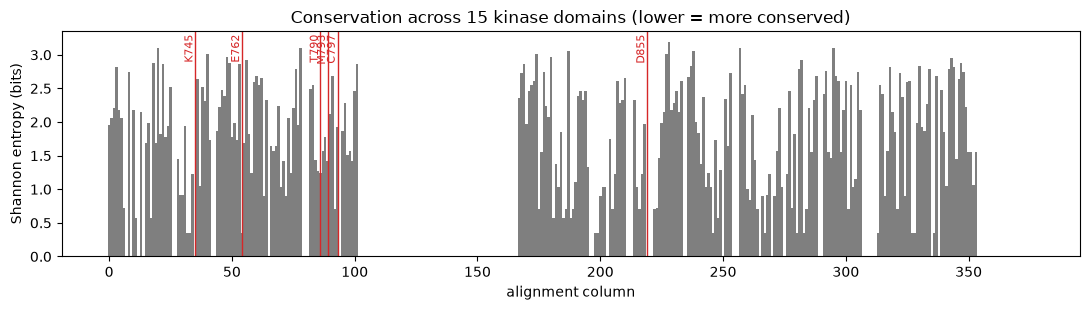

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(arr.shape[1])
ax.bar(x, np.nan_to_num(entropy, nan=0), width=1.0, color="tab:gray")
for r, label in key.items():
    ax.axvline(egfr_col[r], color="tab:red", lw=1)
    ax.text(egfr_col[r], 3.3, f"{arr[0, egfr_col[r]]}{r}", rotation=90, fontsize=8, ha="right", va="top", color="tab:red")
ax.set_xlabel("alignment column"); ax.set_ylabel("Shannon entropy (bits)")
ax.set_title("Conservation across 15 kinase domains (lower = more conserved)")
plt.tight_layout(); plt.show()

## 6. Running an aligner yourself (optional)

The alignment file was produced with **FAMSA** through its Python binding `pyfamsa` (see
`scripts/refresh_cache.py`). It runs locally in a second, so you can reproduce it.

In [11]:
try:
    import pyfamsa
    recs = list(SeqIO.parse(f"{DATA_DIR}/sequences/kinase_domains.fasta", "fasta"))
    seqs = [pyfamsa.Sequence(r.id.encode(), str(r.seq).encode()) for r in recs]
    result = pyfamsa.Aligner(guide_tree="upgma").align(seqs)
    fresh = {s.id.decode(): s.sequence.decode() for s in result}
    same = all(fresh[n] == str(rec.seq) for n, rec in zip(names, msa))
    print("pyfamsa", pyfamsa.__version__, "| identical to the course alignment:", same)
except ImportError:
    print("pyfamsa is not installed: pip install pyfamsa")

pyfamsa 0.7.0 | identical to the course alignment: True


### ✏️ Exercise 1

Which EGFR residues in the kinase domain sit in **fully conserved** columns (entropy 0, no gaps)? Print
the first 15 as e.g. `G719`.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
col_to_res = {c: r for r, c in egfr_col.items()}
conserved = [f"{arr[0, j]}{col_to_res[j]}" for j in range(arr.shape[1])
             if entropy[j] == 0 and gap_frac[j] == 0 and j in col_to_res]
print(len(conserved), "conserved residues:", conserved[:15])
```

</details>

### ✏️ Exercise 2

Make a sub-alignment of only the human ErbB family (EGFR, ERBB2, ERBB3, ERBB4) and compute how many
columns are identical across these four.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
erbb = [i for i, n in enumerate(names) if n in ("EGFR_HUMAN", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN")]
sub = arr[erbb]
identical = sum(len(set(sub[:, j])) == 1 and sub[0, j] != "-" for j in range(sub.shape[1]))
print(identical, "identical columns out of", sub.shape[1])
```

</details>

### ✏️ Exercise 3

The **HRD** and **DFG** motifs are hallmarks of kinases. Find the alignment column of EGFR's DFG
(residues 855-857) and print the three-residue motif for every kinase.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for n, row in zip(names, arr):
    print(f"{n:<13}", "".join(row[egfr_col[855]: egfr_col[857] + 1]))
```

</details>

## Key takeaways

- `AlignIO.read/write` handles Clustal, FASTA, Stockholm, PHYLIP…; `np.array(alignment)` enables column math.
- Entropy and consensus summarize conservation; map residue numbers to columns before interpreting.
- Conserved catalytic residues vs. variable gatekeeper/cysteine positions explain inhibitor selectivity.

**Next:** [08 · BLAST](08_blast_search_parsing.ipynb).